# 课程内插图的代码

In [1]:
# Required packages for this notebook: torch, matplotlib, numpy, torchdiffeq
# If needed, install them with: pip install torch matplotlib numpy torchdiffeq

import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import scipy
from scipy.integrate import solve_ivp


plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 16,
})

# 配置常见中文字体，避免图标题和图例乱码
plt.rcParams["font.sans-serif"] = ["PingFang SC", "Hiragino Sans GB", "Heiti SC", "STHeiti", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

模拟继电负反馈系统：
\begin{align*}
    \Phi(e)
     = \left\{
        \begin{array}{ll}
            M & e > 0 \\
            -M & e < 0 \\
            0 & e = 0
        \end{array}
     \right.
    &&
    G(s) = \frac{1-s}{(s+1)^2}.
\end{align*}
令误差信号 $e=-y$，则闭环继电反馈系统可写成两个耦合的一阶微分方程：
\begin{align*}
    \dot x_1 &= -x_1 + \Phi(-y),\\
    \dot x_2 &= -x_2 + x_1,\\
    y &= 2x_2 - x_1.
\end{align*}
下面同时给出开环响应与继电反馈响应，便于直接对比。

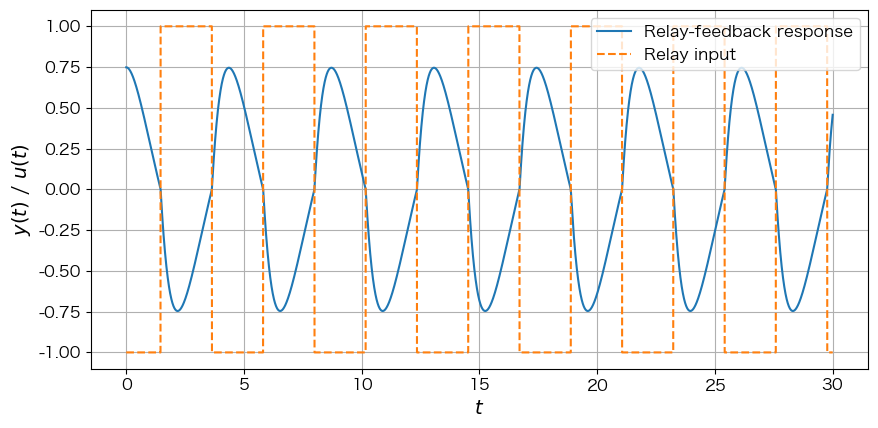

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# Parameters
# ============================================================

M = 1.0

t0 = 0.0
tf = 30.0
t_eval = np.linspace(t0, tf, 6000)

# A nonzero initial condition is necessary.
# If x(0) = 0, then e(0) = 0 and the system stays at the origin.
x0 = np.array([-0.12395111681702752, 0.31223171452305704])


# ============================================================
# Relay nonlinearity
# ============================================================

def Phi(e):
    if e > 0:
        return M
    elif e < 0:
        return -M
    else:
        return 0.0


# ============================================================
# Open-loop system: u = 0
#
#   x1_dot = -x1
#   x2_dot = -x2 + x1
#   y      = 2*x2 - x1
# ============================================================

def open_loop(t, x):
    x1, x2 = x

    dx1 = -x1
    dx2 = -x2 + x1

    return [dx1, dx2]


sol_open = solve_ivp(
    open_loop,
    [t0, tf],
    x0,
    t_eval=t_eval,
    rtol=1e-8,
    atol=1e-10,
    max_step=0.01
)

x1_open = sol_open.y[0]
x2_open = sol_open.y[1]
y_open = 2 * x2_open - x1_open


# ============================================================
# Relay feedback system
#
#   e = -y
#   u = Phi(e)
#
#   x1_dot = -x1 + Phi(-y)
#   x2_dot = -x2 + x1
#   y      = 2*x2 - x1
# ============================================================

def relay_feedback(t, x):
    x1, x2 = x

    y = 2 * x2 - x1
    e = -y
    u = Phi(e)

    dx1 = -x1 + u
    dx2 = -x2 + x1

    return [dx1, dx2]


sol_closed = solve_ivp(
    relay_feedback,
    [t0, tf],
    x0,
    t_eval=t_eval,
    rtol=1e-8,
    atol=1e-10,
    max_step=0.01
)

x1_closed = sol_closed.y[0]
x2_closed = sol_closed.y[1]

y_closed = 2 * x2_closed - x1_closed
e_closed = -y_closed

u_closed = np.array([Phi(e) for e in e_closed])


# ============================================================
# Plot: open-loop vs relay-feedback response
# ============================================================

plt.figure(figsize=(9, 4.5))

# plt.plot(sol_open.t, y_open,
#          label='Open-loop response')

plt.plot(sol_closed.t, y_closed,
         label='Relay-feedback response')

plt.plot(sol_closed.t, u_closed,
         label='Relay input',linestyle='--')

plt.xlabel(r'$t$')
plt.ylabel(r'$y(t)$ / $u(t)$')
plt.grid(True)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


# ============================================================
# Plot the relay input u(t)
# ============================================================

# plt.figure(figsize=(9, 3.5))

# plt.plot(sol_closed.t, u_closed)

# plt.xlabel(r'$t$')
# plt.ylabel(r'$u(t)=\Phi(e(t))$')
# plt.grid(True)
# plt.tight_layout()
# plt.show()

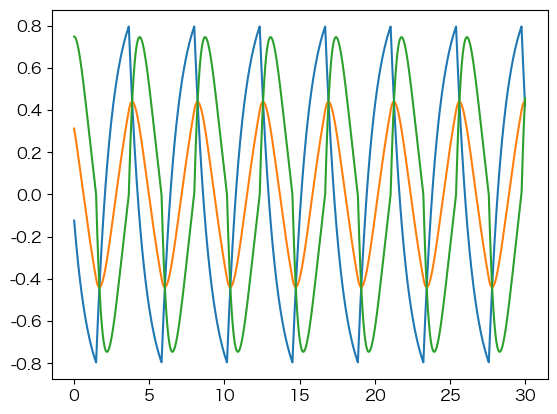

In [19]:
plt.plot(sol_closed.t, x1_closed)
plt.plot(sol_closed.t, x2_closed)
plt.plot(sol_closed.t, y_closed)

In [45]:
i = np.argmax(y_closed)
# print(x1_closed[i], x2_closed[i], y_closed[i])
print("幅度", y_closed[i])
# 频率
i_next = np.argmax(y_closed[100:]) + 100
print("频率", 1/sol_closed.t[i_next])

幅度 0.7484145458631416
频率 0.22931957186544344


In [42]:
sol_closed.t[100]

np.float64(0.5000833472245374)

array([0.74836415, 0.74827418, 0.74814159, ..., 0.44326561, 0.45034889,
       0.45732558], shape=(5998,))

我们继续考虑本章节的例子。在这个问题中，描述函数可以写为
\begin{align*}
        N_1(a_1) 
        & = \frac{2M}{\pi a_1}
\end{align*}

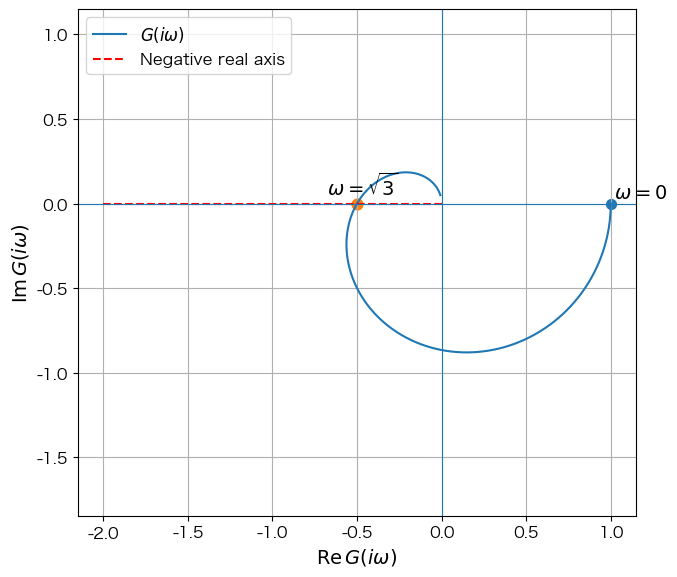

omega* = 1.7320508075688772
G(i omega*) = (-0.5000000000000001-6.672107397796064e-17j)


In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Frequency range
omega = np.linspace(0, 20, 5000)

# G(i omega) = (1 - i omega) / (1 + i omega)^2
s = 1j * omega
G = (1 - s) / (1 + s)**2

# Intersection point
omega_star = np.sqrt(3)
G_star = (1 - 1j * omega_star) / (1 + 1j * omega_star)**2

# Plot
plt.figure(figsize=(7, 6))

plt.plot(G.real, G.imag, label=r'$G(i\omega)$')

# plot the negative real axis
plt.plot([-2, 0], [0, 0], 'r--', label=r'Negative real axis')

# Mark omega = 0
plt.scatter([1], [0], s=50)
plt.text(1.02, 0.03, r'$\omega=0$')

# Mark omega = sqrt(3)
plt.scatter([G_star.real], [G_star.imag], s=60)
plt.text(
    G_star.real - 0.18,
    G_star.imag + 0.05,
    r'$\omega=\sqrt{3}$'
)

# Axes
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel(r'$\mathrm{Re}\,G(i\omega)$')
plt.ylabel(r'$\mathrm{Im}\,G(i\omega)$')

plt.axis('equal')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("omega* =", omega_star)
print("G(i omega*) =", G_star)

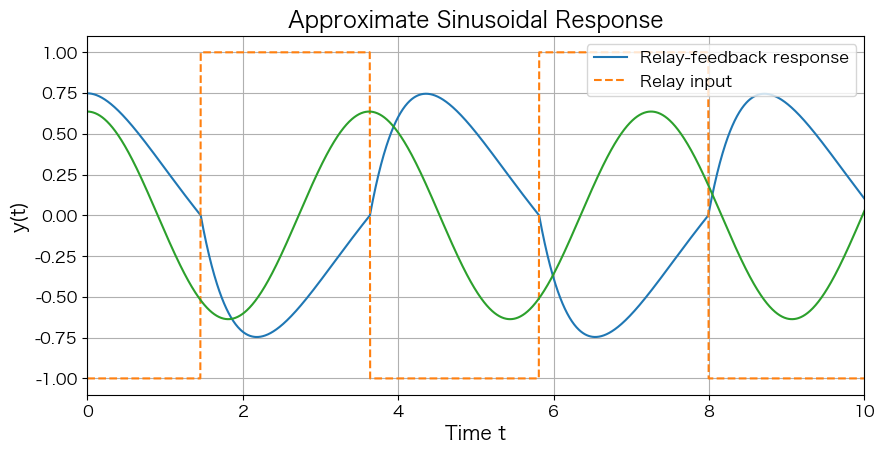

In [27]:
a1 = 1/np.pi
omega = np.sqrt(3)

plt.figure(figsize=(9, 4.5))

# plt.plot(sol_open.t, y_open,
#          label='Open-loop response')

plt.plot(sol_closed.t, y_closed,
         label='Relay-feedback response')

plt.plot(sol_closed.t, u_closed,
         label='Relay input',linestyle='--')

plt.xlabel(r'$t$')
plt.ylabel(r'$y(t)$ / $u(t)$')
plt.grid(True)
plt.legend(loc='upper right')
plt.tight_layout()
# plt.show()

# plot the approximate sinusoidal response
t = sol_closed.t
y = 2 * a1 * np.cos(omega * t)
plt.plot(t, y)
plt.xlabel('Time t')
plt.ylabel('y(t)')
plt.xlim([t[0], 10])
plt.title('Approximate Sinusoidal Response')
plt.grid(True)
plt.show()



In [28]:
np.sqrt(3)

np.float64(1.7320508075688772)